# Proyecto Final Regresión
# Carlos Arcila

## Dataset: Heart Failure Prediction Dataset (Kaggle), archivo heart.csv con 918 registros y 12 variables.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Preparación de datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

data = pd.read_csv('/content/drive/MyDrive/Proyecto - Minería de Datos/heart.csv')
data.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
#Corrección tipos de datos
data['Sex']=data['Sex'].astype('category')
data['ChestPainType']=data['ChestPainType'].astype('category')
data['FastingBS']=data['FastingBS'].astype('category')
data['RestingECG']=data['RestingECG'].astype('category')
data['ExerciseAngina']=data['ExerciseAngina'].astype('category')
data['ST_Slope']=data['ST_Slope'].astype('category')
data['HeartDisease']=data['HeartDisease'].astype('category')


In [ ]:
# Confirmar corrección de tipos de datos
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Age             918 non-null    int64   
 1   Sex             918 non-null    category
 2   ChestPainType   918 non-null    category
 3   RestingBP       918 non-null    int64   
 4   Cholesterol     918 non-null    int64   
 5   FastingBS       918 non-null    category
 6   RestingECG      918 non-null    category
 7   MaxHR           918 non-null    int64   
 8   ExerciseAngina  918 non-null    category
 9   Oldpeak         918 non-null    float64 
 10  ST_Slope        918 non-null    category
 11  HeartDisease    918 non-null    category
dtypes: category(7), float64(1), int64(4)
memory usage: 43.2 KB


In [ ]:
# Copia del dataset antes de editarlo
dataset = data.copy()
dataset.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
# Selección de variables
# Objetivo: estimar de forma continua la Frecuencia Cardíaca Máxima (MaxHR)
# Variable objetivo (Y): MaxHR (numérica continua)

# Se elimina la variable HeartDisease para evitar data leakage
dataset = dataset.drop('HeartDisease', axis=1)

# Ordena la variable objetivo nueva MaxHR para el final
dataset['MaxHR'] = dataset.pop('MaxHR')
dataset.head()


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,ExerciseAngina,Oldpeak,ST_Slope,MaxHR
0,40,M,ATA,140,289,0,Normal,N,0.0,Up,172
1,49,F,NAP,160,180,0,Normal,N,1.0,Flat,156
2,37,M,ATA,130,283,0,ST,N,0.0,Up,98
3,48,F,ASY,138,214,0,Normal,Y,1.5,Flat,108
4,54,M,NAP,150,195,0,Normal,N,0.0,Up,122


# Exploratory Data Analysis (EDA)

In [ ]:
# Revisar nulos
dataset.isnull().sum() # Se confirma que no hay nulos

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
ExerciseAngina,0
Oldpeak,0
ST_Slope,0


In [ ]:
# Análisis estadístico descriptivo
# Revisar y comparar contra el diccionario de datos y las reglas de calidad

# Datos numéricos
dataset.describe()

,Age,RestingBP,Cholesterol,Oldpeak,MaxHR
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.887364,136.809368
std,9.432617,18.514154,109.384145,1.066570,25.460334
min,28.000000,0.000000,0.000000,-2.600000,60.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000
50%,54.000000,130.000000,223.000000,0.600000,138.000000
75%,60.000000,140.000000,267.000000,1.500000,156.000000
max,77.000000,200.000000,603.000000,6.200000,202.000000


In [ ]:
# datos categóricos:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'FastingBS']

for col in cat_cols:
    print(dataset[col].value_counts(), "\n")

Sex
M    725
F    193
Name: count, dtype: int64 

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64 

RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64 

ExerciseAngina
N    547
Y    371
Name: count, dtype: int64 

ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64 

FastingBS
0    704
1    214
Name: count, dtype: int64 



Reglas de calidad variables numéricas:

- Age: SI pasa verificación (18-100)
- RestingBP: NO pasa verificación (80-220)
- Cholesterol: NO pasa verificación (100-603)
- Oldpeak: SI pasa verificación (-2.6-6.2)
- MaxHR: SI pasa verificación (60-220)

Reglas de calidad variables categóricas:
- Sex: SI pasa verificación (M y F)
- ChestPainType: SI pasa verificación (TA, ATA, NAP, NAP, ASY)
- RestingECG: SI pasa verificación (Normal, ST, LVH)
- ExerciseAngina: SI pasa verificación (Y, N)
- ST_Slope: SI pasa verificación (Up, Flat, Down)
- FastingBS: SI pasa verificación (0 y 1)

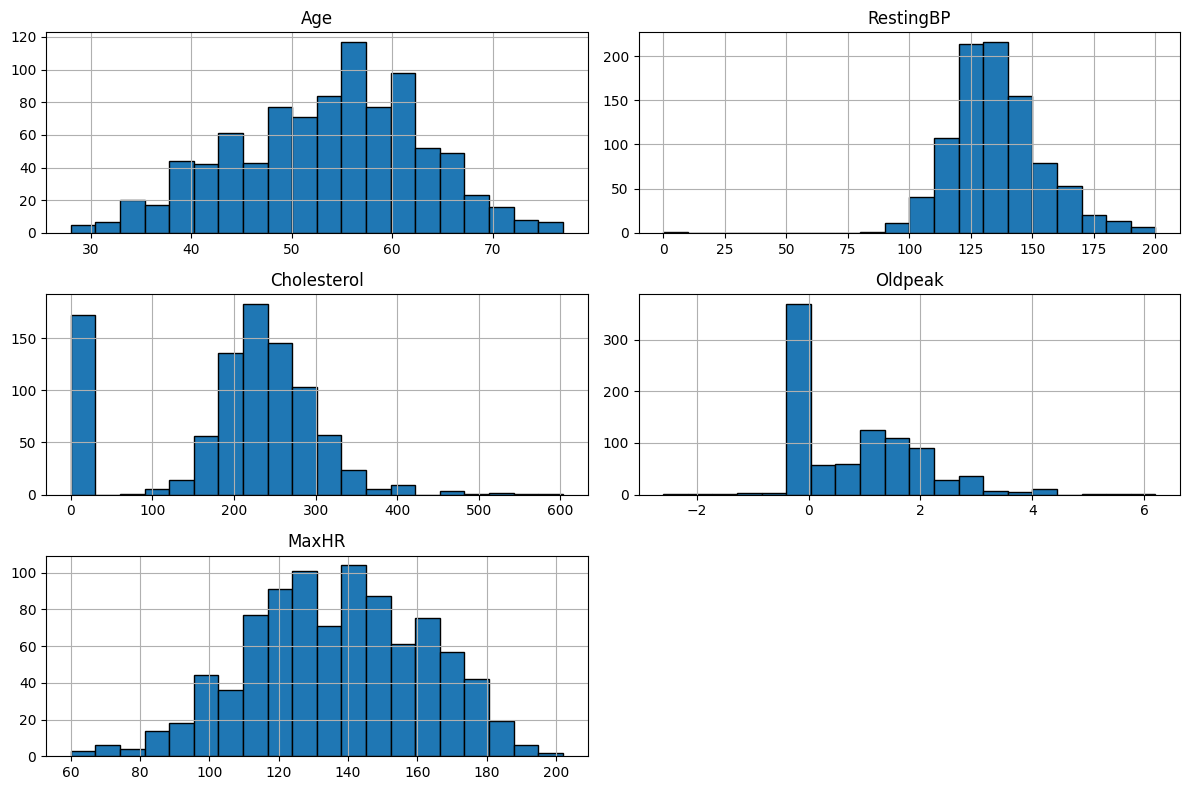

In [ ]:
import matplotlib.pyplot as plt

# Variables numéricas
dataset.hist(figsize=(12, 8), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

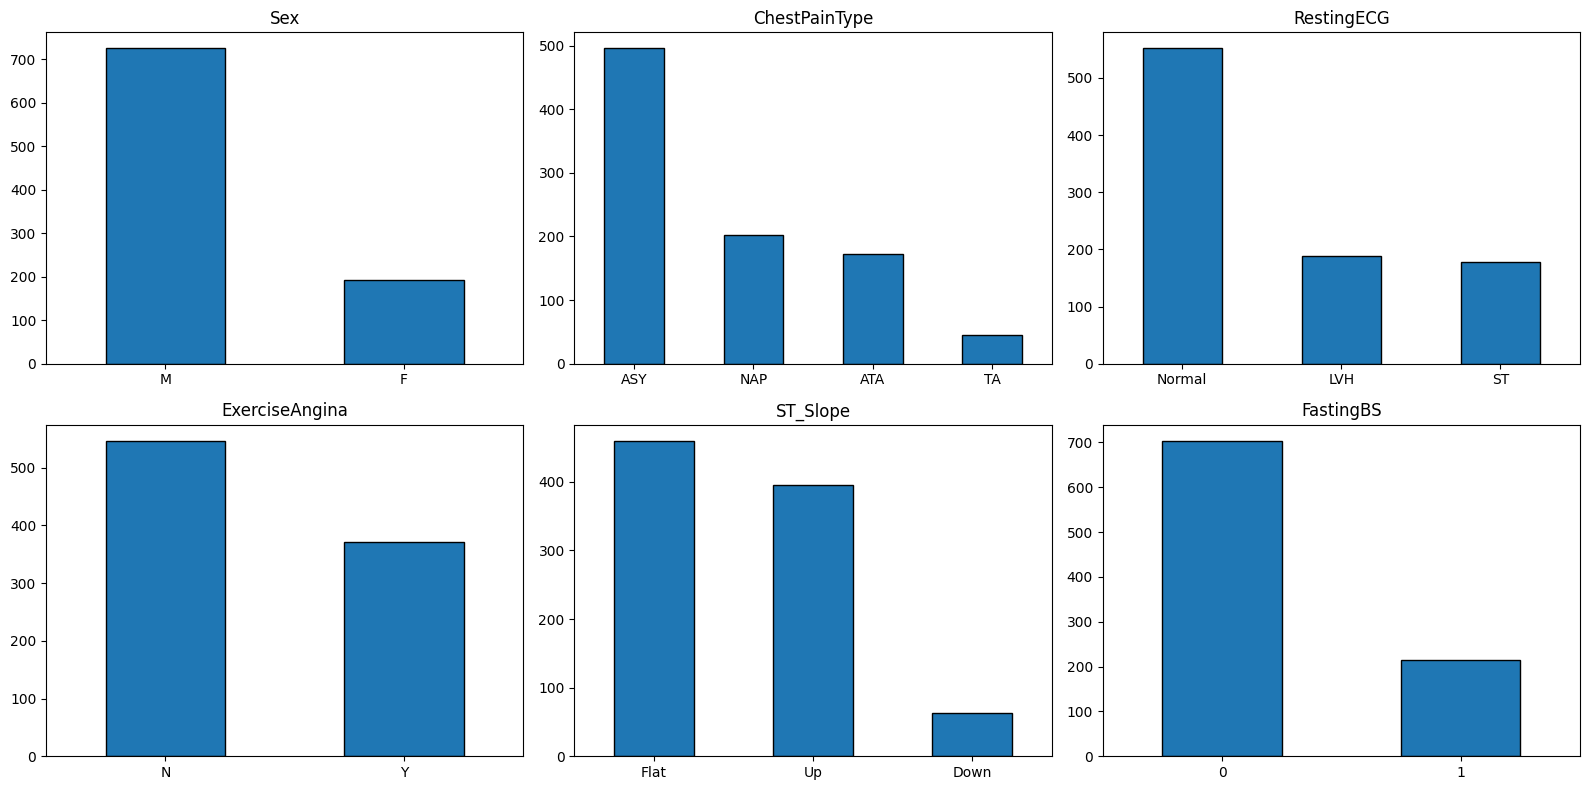

In [ ]:
# Variables categóricas

cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'FastingBS']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    dataset[col].value_counts().plot(kind='bar', ax=axes[i], edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Limpieza de atípicos y errores

In [ ]:
# Cuáles son los valores atípicos:
fuera_bp = dataset[~dataset['RestingBP'].between(80, 220)]
fuera_chol = dataset[~dataset['Cholesterol'].between(100, 603)]

print(f"RestingBP fuera de rango: {len(fuera_bp)}")
print(f"Cholesterol fuera de rango: {len(fuera_chol)}")

RestingBP fuera de rango: 1
Cholesterol fuera de rango: 173


In [ ]:
fuera_bp['RestingBP'].value_counts()


,count
RestingBP,
0,1


In [ ]:
fuera_chol['Cholesterol'].value_counts()

,count
Cholesterol,
0,172
85,1


In [ ]:
# Se imputa el valor de RestingBP con la media (media sin contar el valor 0)

mask = ~dataset['RestingBP'].between(80, 220)
media_bp = round(dataset.loc[~mask, 'RestingBP'].mean())

dataset.loc[mask, 'RestingBP'] = media_bp
print(f"Media usada: {media_bp:.2f}")
print(dataset['RestingBP'].min())

Media usada: 133.00
80


In [ ]:
# Para Cholesterol, se elimina la variable. 172 valores nulos, que equivalen aproximadamente al 19 % de los registros
dataset = dataset.drop('Cholesterol', axis=1)
dataset.head()


,Age,Sex,ChestPainType,RestingBP,FastingBS,RestingECG,ExerciseAngina,Oldpeak,ST_Slope,MaxHR
0,40,M,ATA,140,0,Normal,N,0.0,Up,172
1,49,F,NAP,160,0,Normal,N,1.0,Flat,156
2,37,M,ATA,130,0,ST,N,0.0,Up,98
3,48,F,ASY,138,0,Normal,Y,1.5,Flat,108
4,54,M,NAP,150,0,Normal,N,0.0,Up,122


In [ ]:
# Análisis de correlación entre variables y objetivo
dataset.corr(numeric_only=True)['MaxHR'].sort_values(ascending=False)

# Durante el análisis con WEKA tampoco dio una correlación relevante entre variables y objetivo

,MaxHR
MaxHR,1.000000
RestingBP,-0.109642
Oldpeak,-0.160691
Age,-0.382045


In [ ]:
# dataset de limpieza

dataset.tail()

,Age,Sex,ChestPainType,RestingBP,FastingBS,RestingECG,ExerciseAngina,Oldpeak,ST_Slope,MaxHR
913,45,M,TA,110,0,Normal,N,1.2,Flat,132
914,68,M,ASY,144,1,Normal,N,3.4,Flat,141
915,57,M,ASY,130,0,Normal,Y,1.2,Flat,115
916,57,F,ATA,130,0,LVH,N,0.0,Flat,174
917,38,M,NAP,138,0,Normal,N,0.0,Up,173


In [ ]:
# Variables categóricas a dummies

dataset = pd.get_dummies(dataset, columns=['ChestPainType', 'RestingECG','ST_Slope'], drop_first=False, dtype=int) # varias categorías
dataset = pd.get_dummies(dataset, columns=['Sex', 'ExerciseAngina'], drop_first=True, dtype=int) # dos categorías
dataset.head()

,Age,RestingBP,FastingBS,Oldpeak,MaxHR,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up,Sex_M,ExerciseAngina_Y
0,40,140,0,0.0,172,0,1,0,0,0,1,0,0,0,1,1,0
1,49,160,0,1.0,156,0,0,1,0,0,1,0,0,1,0,0,0
2,37,130,0,0.0,98,0,1,0,0,0,0,1,0,0,1,1,0
3,48,138,0,1.5,108,1,0,0,0,0,1,0,0,1,0,0,1
4,54,150,0,0.0,122,0,0,1,0,0,1,0,0,0,1,1,0


In [ ]:
dataset_clean = dataset.copy()
dataset_clean.to_csv('/content/drive/MyDrive/Proyecto - Minería de Datos/heart_clean_reg.csv', index=False)

In [5]:
# Punto de inicio para evitar ejecutar todo el notebook nuevamente
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

ruta = '/content/drive/MyDrive/Proyecto - Minería de Datos/heart_clean_reg.csv'
dataset_clean = pd.read_csv(ruta)
dataset_clean.tail()

Mounted at /content/drive


,Age,RestingBP,FastingBS,Oldpeak,MaxHR,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up,Sex_M,ExerciseAngina_Y
913,45,110,0,1.2,132,0,0,0,1,0,1,0,0,1,0,1,0
914,68,144,1,3.4,141,1,0,0,0,0,1,0,0,1,0,1,0
915,57,130,0,1.2,115,1,0,0,0,0,1,0,0,1,0,1,1
916,57,130,0,0.0,174,0,1,0,0,1,0,0,0,1,0,0,0
917,38,138,0,0.0,173,0,0,1,0,0,1,0,0,0,1,1,0


No se normaliza antes del split: el scaler aprendería min/max del conjunto de prueba (data leakage).

# 2. Validación Cruzada

In [6]:
#Validación Cruzada
from sklearn.model_selection import cross_validate, KFold

#Dataframe para comparar los modelos
comparacion_CV=pd.DataFrame()

#Medidas de evaluación
scoring=('neg_mean_absolute_error', 'neg_mean_squared_error','neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error', 'r2')

# Validación cruzada con 10 folds
cv = KFold(n_splits=10, shuffle=True, random_state=42) # parte los datos aleatoriamente

In [7]:
#Se separa variables predictoras y objetivo

objetivo = 'MaxHR'

X = dataset_clean.drop(objetivo, axis = 1)
Y = dataset_clean[objetivo]
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   RestingBP          918 non-null    int64  
 2   FastingBS          918 non-null    int64  
 3   Oldpeak            918 non-null    float64
 4   ChestPainType_ASY  918 non-null    int64  
 5   ChestPainType_ATA  918 non-null    int64  
 6   ChestPainType_NAP  918 non-null    int64  
 7   ChestPainType_TA   918 non-null    int64  
 8   RestingECG_LVH     918 non-null    int64  
 9   RestingECG_Normal  918 non-null    int64  
 10  RestingECG_ST      918 non-null    int64  
 11  ST_Slope_Down      918 non-null    int64  
 12  ST_Slope_Flat      918 non-null    int64  
 13  ST_Slope_Up        918 non-null    int64  
 14  Sex_M              918 non-null    int64  
 15  ExerciseAngina_Y   918 non-null    int64  
dtypes: float64(1), int64(15)
m

# 3. Modelos

## Random Forest

In [22]:
#Random forest
from sklearn import ensemble
modelRf = ensemble.RandomForestRegressor(n_estimators=150, max_samples=0.8, criterion='squared_error', min_samples_leaf=20, max_depth=3, max_features=0.5, random_state=42)
modelRf.fit(X, Y)

scores = cross_validate(modelRf, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)
scores=pd.DataFrame(scores) #Se almacenan los resultados en un dataframe
scores

,fit_time,score_time,test_neg_mean_absolute_error,train_neg_mean_absolute_error,test_neg_mean_squared_error,train_neg_mean_squared_error,test_neg_root_mean_squared_error,train_neg_root_mean_squared_error,test_neg_mean_absolute_percentage_error,train_neg_mean_absolute_percentage_error,test_r2,train_r2
0,0.367561,0.033273,-17.954919,-16.994734,-502.148307,-440.378219,-22.408666,-20.985190,-0.132155,-0.135871,0.287889,0.310442
1,0.526065,0.032731,-18.223862,-16.823971,-514.061344,-432.985558,-22.672921,-20.808305,-0.145283,-0.133887,0.172112,0.334323
2,0.504653,0.043088,-21.221541,-16.567892,-684.897264,-416.191225,-26.170542,-20.400765,-0.189122,-0.130202,0.190105,0.330153
3,0.442457,0.040728,-18.169772,-16.853663,-457.439601,-440.035586,-21.387838,-20.977025,-0.146130,-0.134389,0.285382,0.320630
4,0.238371,0.020020,-15.421129,-17.210976,-391.009486,-446.947553,-19.773960,-21.141134,-0.122910,-0.136928,0.306452,0.319541
5,0.240589,0.019933,-17.807105,-17.001781,-491.306997,-440.736677,-22.165446,-20.993729,-0.147027,-0.134754,0.409584,0.296702
6,0.236991,0.019523,-16.507355,-17.078194,-388.496726,-448.244219,-19.710320,-21.171779,-0.121816,-0.136514,0.337318,0.314058
7,0.258662,0.019398,-18.777940,-16.786246,-509.192590,-435.339950,-22.565296,-20.864802,-0.152299,-0.133026,0.177743,0.330857
8,0.316551,0.027242,-14.550217,-17.329789,-320.285904,-457.760304,-17.896533,-21.395334,-0.111038,-0.138239,0.358500,0.310324
9,0.379287,0.025382,-16.118379,-17.098553,-404.190827,-447.223406,-20.104498,-21.147657,-0.122117,-0.136846,0.174372,0.327382


In [23]:
# Promedios para verificar overfitting comparando medidas en train y test
scores.mean()

#Cuidado overfitting, más de 5 puntos de diferencia

,0
fit_time,0.351119
score_time,0.028132
test_neg_mean_absolute_error,-17.475222
train_neg_mean_absolute_error,-16.974580
test_neg_mean_squared_error,-466.302905
train_neg_mean_squared_error,-440.584270
test_neg_root_mean_squared_error,-21.485602
train_neg_root_mean_squared_error,-20.988572
test_neg_mean_absolute_percentage_error,-0.138990
train_neg_mean_absolute_percentage_error,-0.135066


In [24]:
#Se almacena en el df la medida a comparar
comparacion_CV['RF']=scores['test_neg_mean_absolute_error']
comparacion_CV

,RF
0,-17.954919
1,-18.223862
2,-21.221541
3,-18.169772
4,-15.421129
5,-17.807105
6,-16.507355
7,-18.777940
8,-14.550217
9,-16.118379


## XGBoost

In [25]:
# XGBoost
from xgboost import XGBRegressor

modelXgb = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=1, subsample=0.8, colsample_bytree=0.8, min_child_weight=20, reg_lambda=10, random_state=42, n_jobs=-1)

scores = cross_validate(modelXgb, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)
scores = pd.DataFrame(scores)
scores


,fit_time,score_time,test_neg_mean_absolute_error,train_neg_mean_absolute_error,test_neg_mean_squared_error,train_neg_mean_squared_error,test_neg_root_mean_squared_error,train_neg_root_mean_squared_error,test_neg_mean_absolute_percentage_error,train_neg_mean_absolute_percentage_error,test_r2,train_r2
0,0.116216,0.029660,-17.506681,-17.003967,-484.348541,-440.550995,-22.007919,-20.989307,-0.128316,-0.136070,0.313131,0.310172
1,0.059863,0.010665,-18.510405,-16.837236,-525.383911,-433.463715,-22.921255,-20.819792,-0.147436,-0.134029,0.153878,0.333588
2,0.051154,0.012087,-21.146908,-16.619596,-673.600891,-419.770966,-25.953823,-20.488314,-0.188599,-0.130486,0.203463,0.324392
3,0.154722,0.012088,-18.288301,-16.862864,-463.637115,-441.120697,-21.532234,-21.002874,-0.146857,-0.134283,0.275700,0.318955
4,0.055115,0.011548,-15.547709,-17.198843,-395.248688,-448.582489,-19.880863,-21.179766,-0.123864,-0.136897,0.298932,0.317052
5,0.054876,0.016750,-17.977554,-17.039608,-489.272156,-443.864716,-22.119497,-21.068096,-0.148467,-0.135125,0.412030,0.291711
6,0.056120,0.011119,-16.153742,-17.130751,-376.224091,-450.968811,-19.396498,-21.236027,-0.118789,-0.137058,0.358252,0.309889
7,0.090640,0.023250,-18.856565,-16.859488,-508.210754,-437.847687,-22.543530,-20.924810,-0.153096,-0.133667,0.179329,0.327002
8,0.055274,0.011066,-14.260782,-17.348024,-308.042419,-458.432617,-17.551138,-21.411039,-0.108722,-0.138415,0.383022,0.309311
9,0.058877,0.030473,-15.913211,-17.107784,-396.570435,-447.562134,-19.914076,-21.155664,-0.120223,-0.136922,0.189938,0.326873


In [26]:
# Promedios para verificar overfitting comparando medidas en train y test
scores.mean()

#Cuidado overfitting, más de 5 puntos de diferencia

,0
fit_time,0.075286
score_time,0.016871
test_neg_mean_absolute_error,-17.416186
train_neg_mean_absolute_error,-17.000816
test_neg_mean_squared_error,-462.053900
train_neg_mean_squared_error,-442.216483
test_neg_root_mean_squared_error,-21.382083
train_neg_root_mean_squared_error,-21.027569
test_neg_mean_absolute_percentage_error,-0.138437
train_neg_mean_absolute_percentage_error,-0.135295


In [27]:
#Se almacena en el df la medida a comparar
comparacion_CV['XGB']=scores['test_neg_mean_absolute_error']
comparacion_CV

,RF,XGB
0,-17.954919,-17.506681
1,-18.223862,-18.510405
2,-21.221541,-21.146908
3,-18.169772,-18.288301
4,-15.421129,-15.547709
5,-17.807105,-17.977554
6,-16.507355,-16.153742
7,-18.777940,-18.856565
8,-14.550217,-14.260782
9,-16.118379,-15.913211


## KNN

In [28]:
# KNN (método perezoso): requiere normalización porque se basa en distancias.
# El scaler va dentro del Pipeline para ajustarse solo con el train de cada fold (evita data leakage).
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler

predictoras_numericas = ['Age', 'RestingBP', 'Oldpeak']   # las dummies y FastingBS ya están en 0/1

prep = ColumnTransformer([('num', MinMaxScaler(), predictoras_numericas)], remainder='passthrough')

model_knn = Pipeline([
    ('prep', prep),
    ('knn', KNeighborsRegressor(n_neighbors=35, metric='euclidean'))
])

scores = cross_validate(model_knn, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)
scores = pd.DataFrame(scores)
scores

,fit_time,score_time,test_neg_mean_absolute_error,train_neg_mean_absolute_error,test_neg_mean_squared_error,train_neg_mean_squared_error,test_neg_root_mean_squared_error,train_neg_root_mean_squared_error,test_neg_mean_absolute_percentage_error,train_neg_mean_absolute_percentage_error,test_r2,train_r2
0,0.014012,0.079480,-19.239441,-16.841646,-569.414383,-445.505118,-23.862405,-21.106992,-0.141888,-0.133490,0.192497,0.302414
1,0.025200,0.046111,-18.404348,-16.919543,-527.517728,-448.003327,-22.967754,-21.166089,-0.145062,-0.133804,0.150441,0.311234
2,0.022397,0.022698,-20.484161,-16.617918,-676.027906,-428.721200,-26.000537,-20.705584,-0.182713,-0.129486,0.200593,0.309986
3,0.012334,0.033409,-17.905280,-16.942580,-446.558092,-456.722692,-21.131921,-21.371071,-0.143496,-0.133818,0.302381,0.294867
4,0.036413,0.053455,-15.573913,-17.183085,-408.237995,-459.860229,-20.204900,-21.444352,-0.122054,-0.135752,0.275893,0.299882
5,0.015319,0.017022,-17.659627,-16.988654,-467.396965,-453.789411,-21.619366,-21.302333,-0.142999,-0.134023,0.438318,0.275874
6,0.036801,0.059667,-16.737267,-17.034071,-432.172138,-456.580287,-20.788750,-21.367739,-0.122240,-0.135186,0.262818,0.301302
7,0.063717,0.016806,-17.499379,-17.052024,-477.343514,-453.281911,-21.848192,-21.290418,-0.142424,-0.133749,0.229174,0.303279
8,0.011358,0.016174,-15.829827,-17.217412,-372.748562,-466.354801,-19.306697,-21.595250,-0.119204,-0.136351,0.253422,0.297375
9,0.011846,0.015386,-15.650863,-17.153636,-408.807751,-458.408185,-20.218995,-21.410469,-0.117414,-0.136108,0.164941,0.310561


In [29]:
# Promedios para verificar overfitting comparando medidas en train y test
scores.mean()

#Cuidado overfitting, más de 5 puntos de diferencia

,0
fit_time,0.024940
score_time,0.036021
test_neg_mean_absolute_error,-17.498411
train_neg_mean_absolute_error,-16.995057
test_neg_mean_squared_error,-478.622504
train_neg_mean_squared_error,-452.722716
test_neg_root_mean_squared_error,-21.794952
train_neg_root_mean_squared_error,-21.276030
test_neg_mean_absolute_percentage_error,-0.137949
train_neg_mean_absolute_percentage_error,-0.134177


In [30]:
#Se almacena en el df la medida a comparar
comparacion_CV['KNN']=scores['test_neg_mean_absolute_error']
comparacion_CV

,RF,XGB,KNN
0,-17.954919,-17.506681,-19.239441
1,-18.223862,-18.510405,-18.404348
2,-21.221541,-21.146908,-20.484161
3,-18.169772,-18.288301,-17.905280
4,-15.421129,-15.547709,-15.573913
5,-17.807105,-17.977554,-17.659627
6,-16.507355,-16.153742,-16.737267
7,-18.777940,-18.856565,-17.499379
8,-14.550217,-14.260782,-15.829827
9,-16.118379,-15.913211,-15.650863


## NN

In [32]:
#Red neuronal
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

model_rn = TransformedTargetRegressor(
    regressor=Pipeline([
        ('prep', prep),
        ('rn', MLPRegressor(activation='relu', hidden_layer_sizes=(20,), solver='sgd',
                            learning_rate='adaptive', learning_rate_init=0.01, momentum=0.9,
                            alpha=3, early_stopping=True, max_iter=1000, random_state=42))
    ]),
    transformer=StandardScaler()
)


scores = cross_validate(model_rn, X, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)
scores = pd.DataFrame(scores)
scores

,fit_time,score_time,test_neg_mean_absolute_error,train_neg_mean_absolute_error,test_neg_mean_squared_error,train_neg_mean_squared_error,test_neg_root_mean_squared_error,train_neg_root_mean_squared_error,test_neg_mean_absolute_percentage_error,train_neg_mean_absolute_percentage_error,test_r2,train_r2
0,1.958292,0.034930,-17.422706,-16.383693,-484.993348,-423.892602,-22.022565,-20.588652,-0.128622,-0.130796,0.312217,0.336256
1,2.134796,0.046936,-17.377744,-16.226107,-487.825020,-414.676136,-22.086761,-20.363598,-0.138522,-0.129049,0.214366,0.362472
2,1.133632,0.015965,-20.100057,-16.042032,-634.676988,-404.624558,-25.192796,-20.115282,-0.179998,-0.126013,0.249491,0.348769
3,0.913723,0.010592,-17.787687,-16.178522,-449.765398,-420.516708,-21.207673,-20.506504,-0.143397,-0.128779,0.297371,0.350766
4,0.368862,0.009132,-15.587226,-16.553865,-413.499019,-430.058885,-20.334675,-20.737861,-0.123556,-0.131696,0.266561,0.345253
5,0.398706,0.010271,-17.481936,-16.410050,-464.390704,-425.119566,-21.549726,-20.618428,-0.143789,-0.130131,0.441930,0.321623
6,0.254592,0.010179,-16.128188,-16.832387,-397.762116,-445.214885,-19.943974,-21.100116,-0.118575,-0.134361,0.321513,0.318694
7,0.464329,0.009323,-17.271901,-16.333027,-456.598577,-421.425247,-21.368167,-20.528645,-0.141074,-0.129475,0.262673,0.352245
8,0.279182,0.010624,-14.455854,-16.995534,-324.563272,-455.244218,-18.015640,-21.336453,-0.109728,-0.135261,0.349932,0.314115
9,0.463961,0.010292,-15.488893,-16.504424,-386.116319,-430.509473,-19.649843,-20.748722,-0.116295,-0.131993,0.211292,0.352520


In [33]:
# Promedios para verificar overfitting comparando medidas en train y test
scores.mean()
#Cuidado overfitting, más de 5 puntos de diferencia

,0
fit_time,0.837007
score_time,0.016824
test_neg_mean_absolute_error,-16.910219
train_neg_mean_absolute_error,-16.445964
test_neg_mean_squared_error,-450.019076
train_neg_mean_squared_error,-427.128228
test_neg_root_mean_squared_error,-21.137182
train_neg_root_mean_squared_error,-20.664426
test_neg_mean_absolute_percentage_error,-0.134356
train_neg_mean_absolute_percentage_error,-0.130756


In [34]:
#Se almacena en el df la medida a comparar
comparacion_CV['NN']=scores['test_neg_mean_absolute_error']
comparacion_CV

,RF,XGB,KNN,NN
0,-17.954919,-17.506681,-19.239441,-17.422706
1,-18.223862,-18.510405,-18.404348,-17.377744
2,-21.221541,-21.146908,-20.484161,-20.100057
3,-18.169772,-18.288301,-17.905280,-17.787687
4,-15.421129,-15.547709,-15.573913,-15.587226
5,-17.807105,-17.977554,-17.659627,-17.481936
6,-16.507355,-16.153742,-16.737267,-16.128188
7,-18.777940,-18.856565,-17.499379,-17.271901
8,-14.550217,-14.260782,-15.829827,-14.455854
9,-16.118379,-15.913211,-15.650863,-15.488893


## Regresión Lineal

In [35]:
# Regresión lineal: se elimina una dummy por variable multicategoría para evitar colinealidad perfecta.
# Se estandarizan las numéricas solo para poder comparar coeficientes (no cambia las predicciones).
from sklearn.linear_model import LinearRegression

X_lineal = X.drop(columns=['ChestPainType_ASY', 'RestingECG_LVH', 'ST_Slope_Down'])

prep_lin = ColumnTransformer([('num', StandardScaler(), predictoras_numericas)], remainder='passthrough')
model_lr = Pipeline([('prep', prep_lin), ('lr', LinearRegression())])

scores = cross_validate(model_lr, X_lineal, Y, cv=cv, scoring=scoring, return_train_score=True, return_estimator=False)
scores = pd.DataFrame(scores)
scores


,fit_time,score_time,test_neg_mean_absolute_error,train_neg_mean_absolute_error,test_neg_mean_squared_error,train_neg_mean_squared_error,test_neg_root_mean_squared_error,train_neg_root_mean_squared_error,test_neg_mean_absolute_percentage_error,train_neg_mean_absolute_percentage_error,test_r2,train_r2
0,0.076491,0.016825,-16.187074,-16.437788,-442.425230,-424.441994,-21.033907,-20.601990,-0.119431,-0.131142,0.372584,0.335396
1,0.024471,0.037465,-17.963295,-16.249479,-512.720379,-416.157337,-22.643330,-20.399935,-0.143077,-0.129163,0.174272,0.360195
2,0.012856,0.028293,-19.965844,-16.060263,-616.130173,-405.285617,-24.821970,-20.131707,-0.178639,-0.126031,0.271423,0.347705
3,0.034021,0.066603,-17.799476,-16.205422,-452.525447,-422.748153,-21.272646,-20.560840,-0.142088,-0.128958,0.293059,0.347320
4,0.019492,0.016638,-15.597516,-16.453324,-396.953220,-428.670986,-19.923685,-20.704371,-0.124561,-0.130700,0.295909,0.347366
5,0.017246,0.012986,-17.451197,-16.286907,-459.008951,-422.060012,-21.424494,-20.544099,-0.144472,-0.128852,0.448398,0.326505
6,0.010570,0.027797,-15.511550,-16.506165,-361.474285,-432.540380,-19.012477,-20.797605,-0.113951,-0.131814,0.383412,0.338089
7,0.029542,0.030256,-17.158840,-16.372819,-470.224001,-421.659248,-21.684649,-20.534343,-0.138798,-0.129534,0.240671,0.351885
8,0.044574,0.032188,-14.179513,-16.644408,-305.029457,-438.988630,-17.465093,-20.952055,-0.107008,-0.132643,0.389057,0.338606
9,0.029605,0.045562,-15.141345,-16.528120,-379.934376,-430.674623,-19.491905,-20.752702,-0.113405,-0.132022,0.223919,0.352272


In [36]:
# Promedios para verificar overfitting comparando medidas en train y test
scores.mean()
#Cuidado overfitting, más de 5 puntos de diferencia

,0
fit_time,0.029887
score_time,0.031461
test_neg_mean_absolute_error,-16.695565
train_neg_mean_absolute_error,-16.374470
test_neg_mean_squared_error,-439.642552
train_neg_mean_squared_error,-424.322698
test_neg_root_mean_squared_error,-20.877415
train_neg_root_mean_squared_error,-20.597965
test_neg_mean_absolute_percentage_error,-0.132543
train_neg_mean_absolute_percentage_error,-0.130086


In [37]:
#Se almacena en el df la medida a comparar
comparacion_CV['LR']=scores['test_neg_mean_absolute_error']
comparacion_CV

,RF,XGB,KNN,NN,LR
0,-17.954919,-17.506681,-19.239441,-17.422706,-16.187074
1,-18.223862,-18.510405,-18.404348,-17.377744,-17.963295
2,-21.221541,-21.146908,-20.484161,-20.100057,-19.965844
3,-18.169772,-18.288301,-17.905280,-17.787687,-17.799476
4,-15.421129,-15.547709,-15.573913,-15.587226,-15.597516
5,-17.807105,-17.977554,-17.659627,-17.481936,-17.451197
6,-16.507355,-16.153742,-16.737267,-16.128188,-15.511550
7,-18.777940,-18.856565,-17.499379,-17.271901,-17.158840
8,-14.550217,-14.260782,-15.829827,-14.455854,-14.179513
9,-16.118379,-15.913211,-15.650863,-15.488893,-15.141345


## Elección del mejor modelo:

La **regresión lineal** es la mejor opción para predecir MaxHR en un contexto médico y diagnóstico, porque es el modelo más preciso de los cinco:

- Tiene el MAE promedio más bajo en validación cruzada (16.7 lpm, frente a 16.9 de la red neuronal, 17.4 de XGBoost y ~17.5 de Random Forest y KNN)
- Gana en 7 de los 10 folds y además presenta la menor brecha entre entrenamiento y prueba (R² 0.345 contra 0.309), lo que da predicciones más estables y confiables para un uso clínico.
- Es también el modelo más explicable, algo clave en medicina, donde un profesional necesita entender y justificar cada estimación: cada coeficiente indica cuántos latidos por minuto aumenta o disminuye MaxHR por cada variable.
- Por último, es el modelo de menor costo computacional: entrena en milisegundos, no necesita ajustar hiperparámetros, se guarda como un vector de coeficientes y se despliega fácilmente.


# 4. Guardamos el mejor modelo

In [39]:
import pickle
from google.colab import drive
drive.mount('/content/drive')

# Entrenar el modelo final con todos los datos (cross_validate no deja el modelo entrenado)
mejor_modelo = model_lr
mejor_modelo.fit(X_lineal, Y)

# Columnas en el orden exacto que espera el modelo
variables = X_lineal.columns.tolist()

# Guardar en Drive (el scaler va dentro del Pipeline, no se guarda aparte)
ruta = '/content/drive/MyDrive/Proyecto - Minería de Datos/modelo-lr-reg.pkl'
with open(ruta, 'wb') as f:
    pickle.dump([mejor_modelo, variables], f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Conclusiones

### Desempeño del modelo
El modelo seleccionado, **Regresión Lineal**, obtuvo el mejor desempeño entre los cinco evaluados (validación cruzada de 10 folds):

| Métrica | Valor |
|---|---|
| R² (test) | ≈ 0.31 |
| MAE | ≈ 16.7 lpm |
| MAPE | ≈ 13% |

El modelo predice con un error menor al 10% en el rango típico de MaxHR (120–160 lpm), pero falla en los valores extremos, especialmente en pacientes con MaxHR ≤ 100 lpm, donde el MAPE supera el 40%.

### ¿Por qué el modelo no logra una mejor predicción?
1. **Información insuficiente en el dataset:** todos los modelos, desde el más simple (Regresión Lineal) hasta los más complejos (Random Forest, XGBoost, Redes Neuronales), se estancan en un R² ≈ 0.30. El límite no está en el algoritmo, sino en las variables disponibles, que explican solo cerca del 30% de la variación de MaxHR.
2. **Factores determinantes ausentes:** MaxHR depende de variables que no están en el dataset, como la condición física, los medicamentos (por ejemplo, los betabloqueantes reducen la frecuencia cardíaca) y la intensidad o duración real de la prueba de esfuerzo.
3. **Valores extremos poco explicables:** existen registros con MaxHR de 60–80 lpm, valores cercanos a una frecuencia en reposo, que pueden deberse a pruebas suspendidas, condiciones clínicas o errores de registro. El modelo no puede anticiparlos con la información disponible.

### Recomendaciones a nivel del dataset
1. **Incluir más variables clínicas relevantes:**
   - Frecuencia cardíaca en reposo.
   - Uso de medicamentos, especialmente betabloqueantes.
   - Nivel de actividad física o capacidad funcional (METs).
   - Índice de masa corporal (IMC), peso y estatura.
   - Antecedentes de tabaquismo, diabetes e hipertensión.
2. **Registrar el contexto de la prueba de esfuerzo:** duración, protocolo utilizado (por ejemplo, Bruce) y motivo de finalización (máximo esfuerzo alcanzado, síntomas o suspensión médica).
3. **Mejorar la calidad del registro:** validar los valores atípicos con personal clínico y evitar codificar los faltantes como 0.
4. **Estandarizar la medición entre centros:** unificar las definiciones de variables como Oldpeak y Cholesterol.
5. **Aumentar el volumen de datos**, sobre todo en los rangos extremos de MaxHR, que hoy están poco representados.